In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "/kaggle/input/datasets/dhritirajesh/train-data/advanced_features_full_v2.csv"
)

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nTarget distribution:")
print(df["target"].value_counts())

print("\nNumber of trips:", df["trip_id"].nunique())
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (625251, 29)

Columns: ['point_idx', 'arc_id', 'distance_m', 'rank', 'dist_to_start_node', 'dist_to_end_node', 'arc_length', 'road_heading', 'arc_degree', 'speed', 'acceleration', 'heading', 'heading_change', 'time_gap', 'rolling_speed_mean', 'rolling_speed_std', 'time_in_trip', 'heading_diff', 'dist_rank_0', 'dist_rank_1', 'candidate_spread', 'implied_speed', 'next_arc_heading', 'arc_turn_angle', 'prev_dist', 'prev_speed', 'time_since_prev', 'target', 'trip_id']

Target distribution:
target
0    350138
1    275113
Name: count, dtype: int64

Number of trips: 80

Missing values:
point_idx             0
arc_id                0
distance_m            0
rank                  0
dist_to_start_node    0
dist_to_end_node      0
arc_length            0
road_heading          0
arc_degree            0
speed                 0
acceleration          0
heading               0
heading_change        0
time_gap              0
rolling_speed_mean    0
rolling_speed_std     0
time_in_trip    

In [2]:
# Convert angles into circular features
df["heading_sin"] = np.sin(np.radians(df["heading"]))
df["heading_cos"] = np.cos(np.radians(df["heading"]))

df["road_heading_sin"] = np.sin(np.radians(df["road_heading"]))
df["road_heading_cos"] = np.cos(np.radians(df["road_heading"]))

# Features used for training
features = [
    "distance_m",
    "rank",
    "speed",
    "time_gap",
    "heading_diff",
    "prev_dist",
    "heading_sin",
    "heading_cos",
    "road_heading_sin",
    "road_heading_cos"
]

X = df[features]
y = df["target"]
groups = df["trip_id"]

print("Features:", features)
print("X shape:", X.shape)
print("y shape:", y.shape)

Features: ['distance_m', 'rank', 'speed', 'time_gap', 'heading_diff', 'prev_dist', 'heading_sin', 'heading_cos', 'road_heading_sin', 'road_heading_cos']
X shape: (625251, 10)
y shape: (625251,)


In [3]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.3,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))

print("Training trips:", groups.iloc[train_idx].nunique())
print("Validation trips:", groups.iloc[val_idx].nunique())

Training rows: 443904
Validation rows: 181347
Training trips: 56
Validation trips: 24


In [4]:
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [5]:
y_pred = rf_model.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred))
print("Recall:", recall_score(y_val, y_pred))
print("F1 Score:", f1_score(y_val, y_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred))

Accuracy: 0.7433814730875062
Precision: 0.7436318728522336
Recall: 0.7534136284013883
F1 Score: 0.7484907934346137

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.73      0.74     89436
           1       0.74      0.75      0.75     91911

    accuracy                           0.74    181347
   macro avg       0.74      0.74      0.74    181347
weighted avg       0.74      0.74      0.74    181347


Confusion Matrix:
[[65563 23873]
 [22664 69247]]


In [6]:
!pip install xgboost -q

import xgboost as xgb

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [7]:
xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [8]:
y_pred_xgb = xgb_model.predict(X_val)

In [9]:
print("XGBoost Results")

print("Accuracy:", accuracy_score(y_val, y_pred_xgb))
print("Precision:", precision_score(y_val, y_pred_xgb))
print("Recall:", recall_score(y_val, y_pred_xgb))
print("F1 Score:", f1_score(y_val, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_xgb))

XGBoost Results
Accuracy: 0.7439825307283826
Precision: 0.7683394494330317
Recall: 0.7084679744535475
F1 Score: 0.7371900826446282

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.78      0.75     89436
           1       0.77      0.71      0.74     91911

    accuracy                           0.74    181347
   macro avg       0.75      0.74      0.74    181347
weighted avg       0.75      0.74      0.74    181347


Confusion Matrix:
[[69803 19633]
 [26795 65116]]


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [11]:
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [12]:
y_pred_lr = lr_model.predict(X_val)

In [13]:
print("Logistic Regression Results")

print("Accuracy:", accuracy_score(y_val, y_pred_lr))
print("Precision:", precision_score(y_val, y_pred_lr))
print("Recall:", recall_score(y_val, y_pred_lr))
print("F1 Score:", f1_score(y_val, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_lr))

Logistic Regression Results
Accuracy: 0.7598471438733477
Precision: 0.7521271271271271
Recall: 0.7848026895583772
F1 Score: 0.7681175624950084

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.73      0.75     89436
           1       0.75      0.78      0.77     91911

    accuracy                           0.76    181347
   macro avg       0.76      0.76      0.76    181347
weighted avg       0.76      0.76      0.76    181347


Confusion Matrix:
[[65664 23772]
 [19779 72132]]


In [14]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [15]:
train_data = X_train.copy()
train_data["target"] = y_train

class_0 = train_data[train_data["target"] == 0].sample(
    n=min(25000, (train_data["target"] == 0).sum()),
    random_state=42
)

class_1 = train_data[train_data["target"] == 1].sample(
    n=min(25000, (train_data["target"] == 1).sum()),
    random_state=42
)

svm_train = pd.concat([class_0, class_1])

X_svm_train = svm_train[features]
y_svm_train = svm_train["target"]

print("SVM training rows:", len(X_svm_train))

SVM training rows: 50000


In [16]:
rbf_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        cache_size=2000,
        probability=True
    ))
])

rbf_svm.fit(X_svm_train, y_svm_train)

print("RBF SVM training completed!")

RBF SVM training completed!


In [17]:
# Representative validation sample
svm_val = X_val.sample(
    n=min(30000, len(X_val)),
    random_state=42
)

y_svm_val = y_val.loc[svm_val.index]

y_pred_svm = rbf_svm.predict(svm_val)

print("RBF SVM Results")

print("Accuracy:", accuracy_score(y_svm_val, y_pred_svm))
print("Precision:", precision_score(y_svm_val, y_pred_svm))
print("Recall:", recall_score(y_svm_val, y_pred_svm))
print("F1 Score:", f1_score(y_svm_val, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_svm_val, y_pred_svm))

print("\nConfusion Matrix:")
print(confusion_matrix(y_svm_val, y_pred_svm))

RBF SVM Results
Accuracy: 0.7422666666666666
Precision: 0.7355651683280046
Recall: 0.7695284318226536
F1 Score: 0.752163600230784

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.71      0.73     14753
           1       0.74      0.77      0.75     15247

    accuracy                           0.74     30000
   macro avg       0.74      0.74      0.74     30000
weighted avg       0.74      0.74      0.74     30000


Confusion Matrix:
[[10535  4218]
 [ 3514 11733]]


In [18]:
!pip install lightgbm -q

import lightgbm as lgb

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [19]:
lgb_model = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=0.1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(X_train, y_train)

print("LightGBM training completed!")

LightGBM training completed!


In [20]:

# Create a common validation sample for all five models

common_val = X_val.sample(
    n=min(30000, len(X_val)),
    random_state=42
)

common_y = y_val.loc[common_val.index]

# LightGBM predictions
y_pred_lgb = lgb_model.predict(common_val)

print("LIGHTGBM RESULTS")

print("Accuracy:", accuracy_score(common_y, y_pred_lgb))
print("Precision:", precision_score(common_y, y_pred_lgb))
print("Recall:", recall_score(common_y, y_pred_lgb))
print("F1 Score:", f1_score(common_y, y_pred_lgb))

print("\nClassification Report:")
print(classification_report(common_y, y_pred_lgb))

print("\nConfusion Matrix:")
print(confusion_matrix(common_y, y_pred_lgb))


LIGHTGBM RESULTS
Accuracy: 0.7452
Precision: 0.7426747526332589
Recall: 0.7630353512166328
F1 Score: 0.7527173913043478

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.73      0.74     14753
           1       0.74      0.76      0.75     15247

    accuracy                           0.75     30000
   macro avg       0.75      0.74      0.74     30000
weighted avg       0.75      0.75      0.75     30000


Confusion Matrix:
[[10722  4031]
 [ 3613 11634]]


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
2,Logistic Regression,0.7619,0.7545,0.7880,0.7709
0,Random Forest,0.7465,0.7460,0.7601,0.7530
4,LightGBM,0.7452,0.7427,0.7630,0.7527
3,RBF SVM,0.7423,0.7356,0.7695,0.7522
1,XGBoost,0.7471,0.7706,0.7153,0.7419


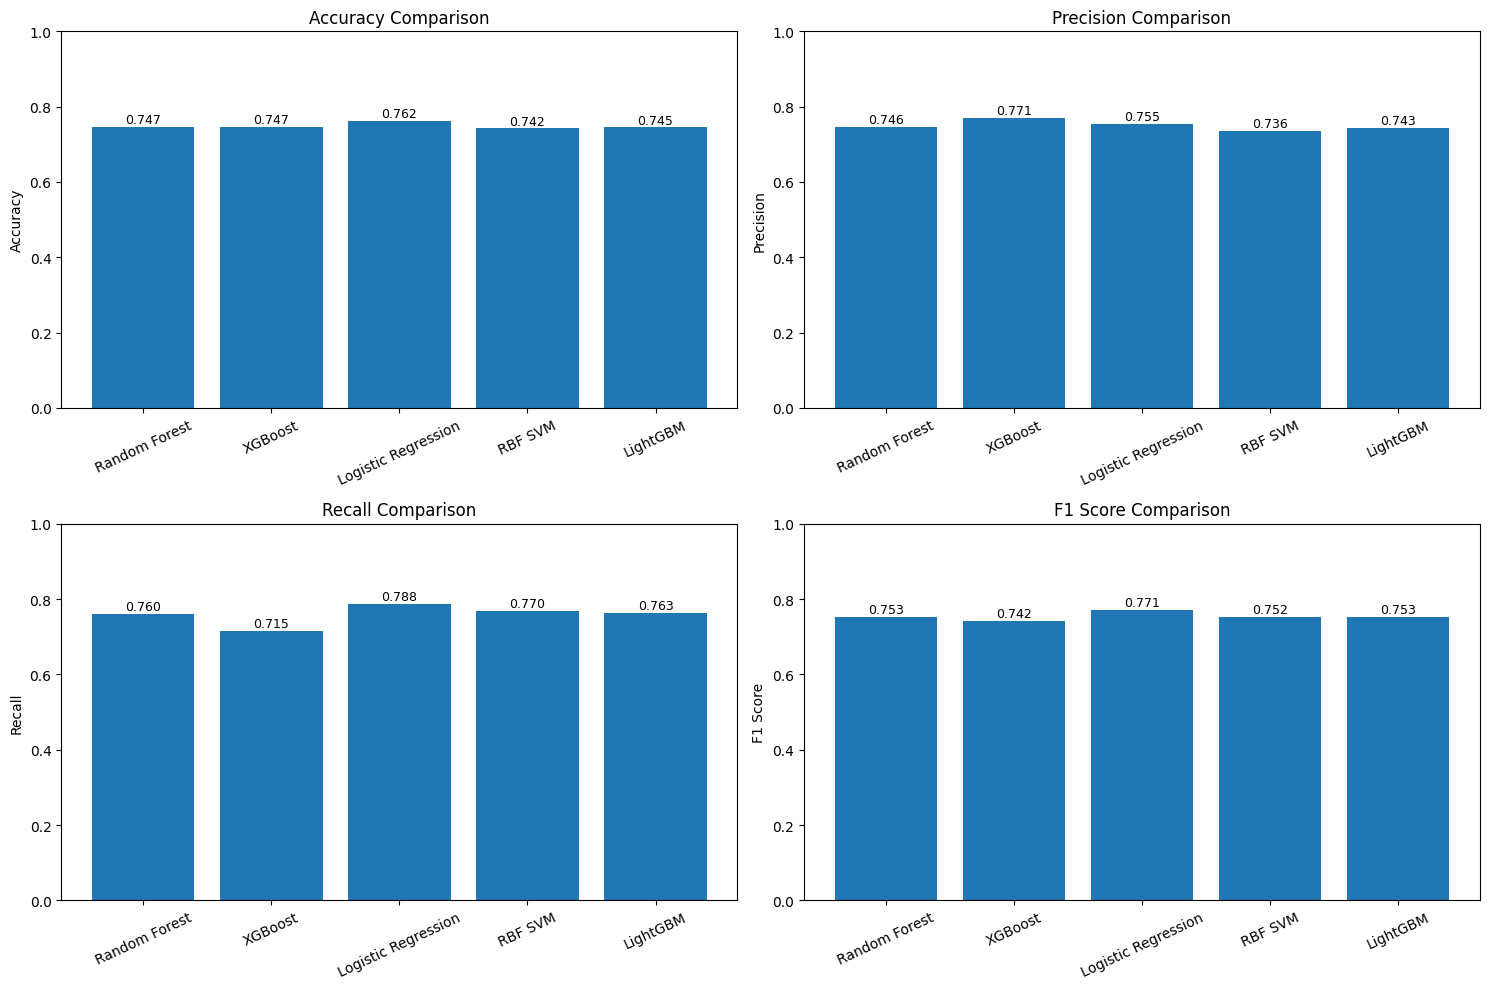

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Use exactly the same validation rows for all models
common_val = X_val.sample(
    n=min(30000, len(X_val)),
    random_state=42
)

common_y = y_val.loc[common_val.index]

# Predict using all five models
predictions = {
    "Random Forest": rf_model.predict(common_val),
    "XGBoost": xgb_model.predict(common_val),
    "Logistic Regression": lr_model.predict(common_val),
    "RBF SVM": rbf_svm.predict(common_val),
    "LightGBM": lgb_model.predict(common_val)
}

# Calculate evaluation metrics
results = []

for model_name, y_pred in predictions.items():

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(common_y, y_pred),
        "Precision": precision_score(common_y, y_pred),
        "Recall": recall_score(common_y, y_pred),
        "F1 Score": f1_score(common_y, y_pred)
    })

comparison_df = pd.DataFrame(results)

# Display comparison table
print("MODEL PERFORMANCE COMPARISON")
display(
    comparison_df.sort_values(
        by="F1 Score",
        ascending=False
    ).round(4)
)

# Plot all four metrics
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, metric in zip(axes.flatten(), metrics):

    bars = ax.bar(
        comparison_df["Model"],
        comparison_df[metric]
    )

    ax.set_title(f"{metric} Comparison")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=25)

    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.01,
            f"{height:.3f}",
            ha="center",
            fontsize=9
        )

plt.tight_layout()
plt.show()

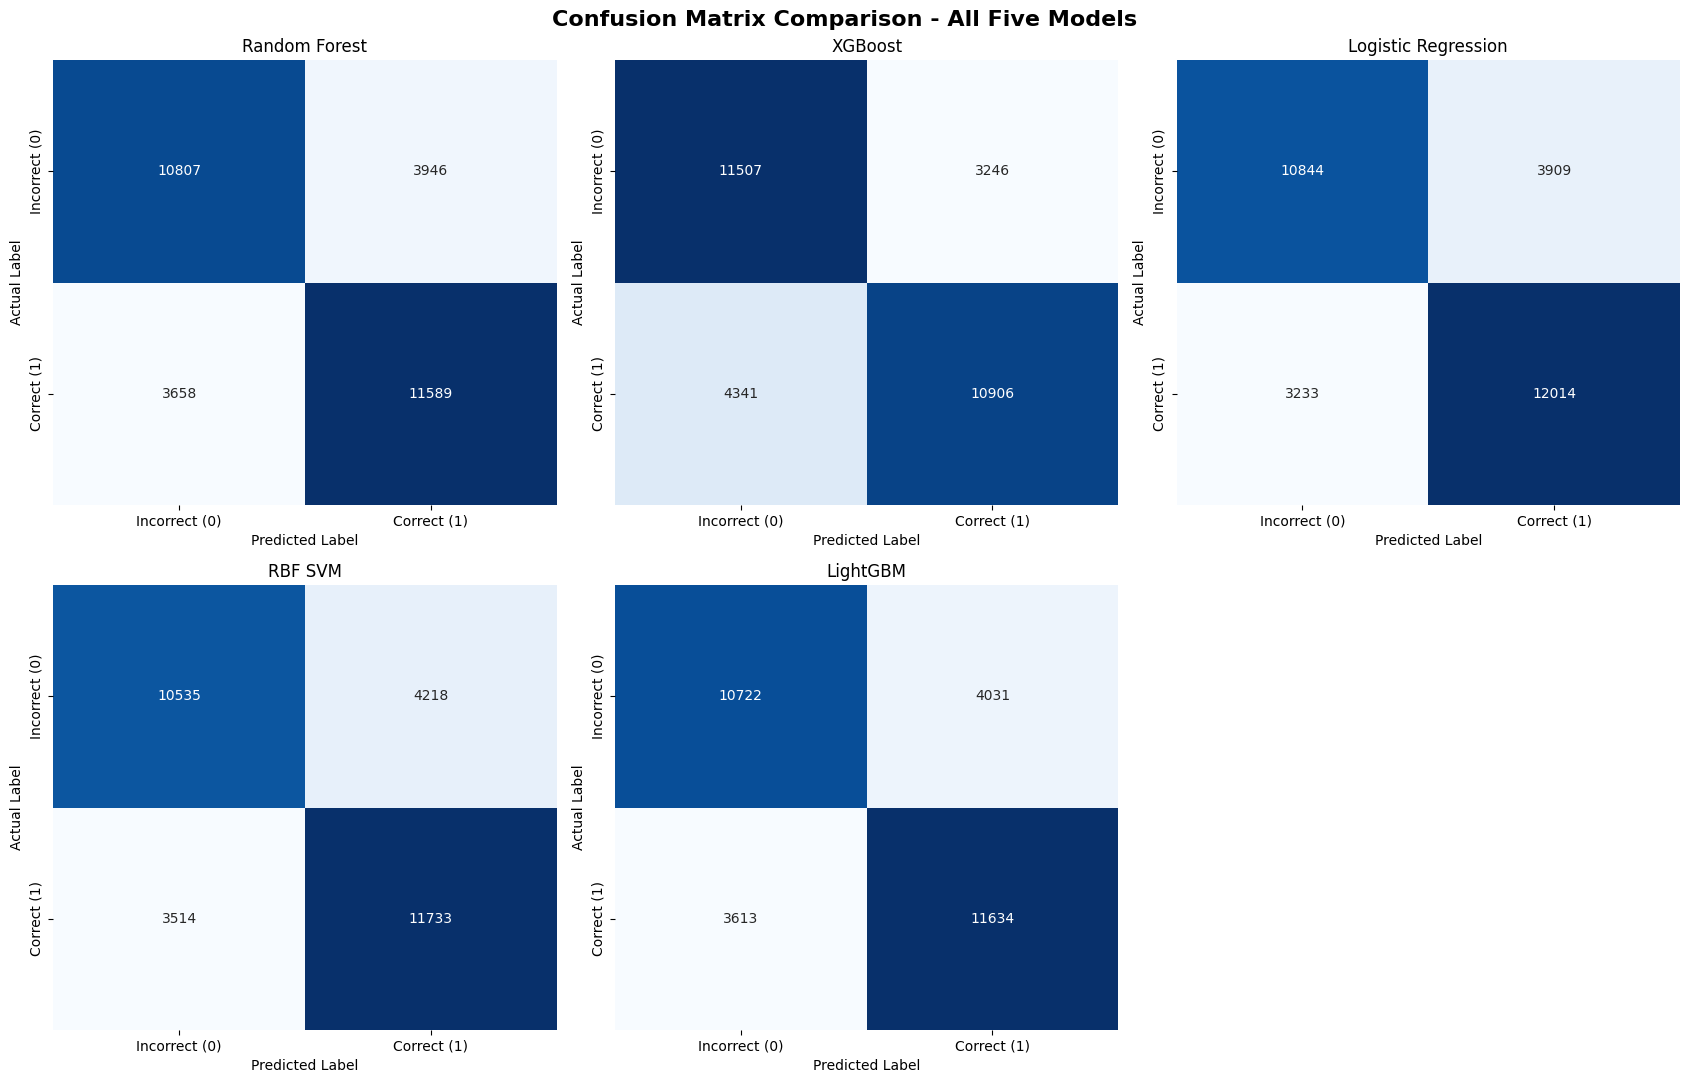

In [22]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate predictions using the common validation dataset
predictions = {
    "Random Forest": rf_model.predict(common_val),
    "XGBoost": xgb_model.predict(common_val),
    "Logistic Regression": lr_model.predict(common_val),
    "RBF SVM": rbf_svm.predict(common_val),
    "LightGBM": lgb_model.predict(common_val)
}

# Plot confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(17, 11))
axes = axes.flatten()

for i, (model_name, y_pred) in enumerate(predictions.items()):

    cm = confusion_matrix(common_y, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Incorrect (0)", "Correct (1)"],
        yticklabels=["Incorrect (0)", "Correct (1)"],
        ax=axes[i]
    )

    axes[i].set_title(f"{model_name}")
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

# Hide the unused sixth subplot
axes[5].axis("off")

plt.suptitle(
    "Confusion Matrix Comparison - All Five Models",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [23]:
import pandas as pd
import numpy as np
import time

from sklearn.base import clone
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.metrics import f1_score, accuracy_score, log_loss

# --------------------------------------------------
# 1. DEFINE FIVE MODELS
# --------------------------------------------------

models = {
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "Logistic Regression": lr_model,
    "RBF SVM": rbf_svm,
    "LightGBM": lgb_model
}

# --------------------------------------------------
# 2. COMMON VALIDATION DATA
# --------------------------------------------------

common_val = X_val.copy()
common_y = y_val.loc[common_val.index]

test_rows = df.loc[common_val.index].copy()

# --------------------------------------------------
# 3. REDUCED GROUP CROSS-VALIDATION DATA
# --------------------------------------------------

cv = GroupKFold(n_splits=3)

# Select 30 representative training trips
unique_groups = groups.loc[X_train.index].unique()

rng = np.random.RandomState(42)

selected_groups = rng.choice(
    unique_groups,
    size=min(30, len(unique_groups)),
    replace=False
)

groups_all = groups.loc[X_train.index]

cv_frame = pd.DataFrame({
    "idx": X_train.index,
    "group": groups_all.values
})

cv_frame = cv_frame[
    cv_frame["group"].isin(selected_groups)
]

# Maximum 200 GPS records per trip
cv_frame = (
    cv_frame.groupby("group", group_keys=False)
    .apply(
        lambda x: x.sample(
            n=min(200, len(x)),
            random_state=42
        )
    )
)

cv_idx = cv_frame["idx"].values

X_cv = X_train.loc[cv_idx]
y_cv = y_train.loc[cv_idx]
groups_cv = groups.loc[cv_idx]

print("CV training rows:", len(X_cv))
print("CV training trips:", groups_cv.nunique())

# --------------------------------------------------
# 4. EVALUATE MODELS
# --------------------------------------------------

results = []

for name, model in models.items():

    print("\nEvaluating:", name)

    # CV model
    cv_model = clone(model)

    # Disable probability calibration during CV.
    # Macro F1 only requires class predictions.
    probability_params = [
        key for key in cv_model.get_params()
        if key.endswith("probability")
    ]

    if probability_params:
        cv_model.set_params(**{
            key: False for key in probability_params
        })

    start_time = time.perf_counter()

    cv_scores = cross_val_score(
        cv_model,
        X_cv,
        y_cv,
        cv=cv,
        groups=groups_cv,
        scoring="f1_macro",
        n_jobs=1
    )

    cv_macro_f1 = cv_scores.mean()

    cv_time = time.perf_counter() - start_time

    print("CV Macro F1:", round(cv_macro_f1, 4))
    print("CV time:", round(cv_time, 2), "seconds")

    # --------------------------------------------------
    # PREDICTIONS ON COMPLETE VALIDATION DATA
    # --------------------------------------------------

    start_time = time.perf_counter()

    y_pred = model.predict(common_val)

    inference_time = time.perf_counter() - start_time

    student_macro_f1 = f1_score(
        common_y,
        y_pred,
        average="macro"
    )

    # --------------------------------------------------
    # TOP-1 CANDIDATE ACCURACY
    # --------------------------------------------------

    probabilities = model.predict_proba(common_val)[:, 1]

    prediction_df = test_rows[
        ["trip_id", "point_idx", "target"]
    ].copy()

    prediction_df["probability"] = probabilities

    top_candidates = (
        prediction_df
        .sort_values("probability", ascending=False)
        .groupby(["trip_id", "point_idx"], sort=False)
        .head(1)
    )

    top1_accuracy = accuracy_score(
        top_candidates["target"],
        np.ones(len(top_candidates), dtype=int)
    )

    # --------------------------------------------------
    # LOG LOSS
    # --------------------------------------------------

    model_log_loss = log_loss(
        common_y,
        probabilities,
        labels=[0, 1]
    )

    # --------------------------------------------------
    # SAVE RESULTS
    # --------------------------------------------------

    results.append({
        "Model": name,
        "CV Macro F1-score": cv_macro_f1,
        "Top-1 Accuracy": top1_accuracy,
        "Student-Test Macro F1-score": student_macro_f1,
        "Log Loss": model_log_loss,
        "Inference Time (seconds)": inference_time
    })

    print("Completed:", name)

# --------------------------------------------------
# 5. FINAL COMPARISON
# --------------------------------------------------

comparison_df = pd.DataFrame(results)

print("\n========== FINAL MODEL COMPARISON ==========")

display(
    comparison_df
    .sort_values(
        by="Student-Test Macro F1-score",
        ascending=False
    )
    .round(4)
)

comparison_df.to_csv(
    "pathsnap_model_comparison.csv",
    index=False
)

print("\nResults saved successfully!")


/tmp/ipykernel_49/2513181619.py:61: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


CV training rows: 6000
CV training trips: 30

Evaluating: Random Forest
CV Macro F1: 0.7709
CV time: 1.8 seconds
Completed: Random Forest

Evaluating: XGBoost
CV Macro F1: 0.7511
CV time: 1.04 seconds
Completed: XGBoost

Evaluating: Logistic Regression
CV Macro F1: 0.7595
CV time: 2.96 seconds
Completed: Logistic Regression

Evaluating: RBF SVM
CV Macro F1: 0.7598
CV time: 1.74 seconds
Completed: RBF SVM

Evaluating: LightGBM
CV Macro F1: 0.7476
CV time: 1.76 seconds
Completed: LightGBM

========== FINAL MODEL COMPARISON ==========


,Model,CV Macro F1-score,Top-1 Accuracy,Student-Test Macro F1-score,Log Loss,Inference Time (seconds)
2,Logistic Regression,0.7595,0.8087,0.7595,0.5481,0.0200
1,XGBoost,0.7511,0.7755,0.7438,0.5659,0.4660
0,Random Forest,0.7709,0.7746,0.7433,0.5387,0.7221
4,LightGBM,0.7476,0.7754,0.7402,0.5604,1.4801
3,RBF SVM,0.7598,0.7682,0.7402,0.5730,159.3625



Results saved successfully!
